## Problem
Fish is the main animal protein for many Sri Lankan households, and consumer prices rose sharply after the 2022 economic crisis.
Fish moves from the **Peliyagoda wholesale market** to retail markets around Colombo (Borella, Nugegoda, Maharagama and others).
**Question:** given this week's wholesale price of a species, what *retail* price should a Colombo shopper expect?
A model like this can flag unusually high retail markups.

**Data:** weekly fish price reports from the Ministry of Fisheries (Rs/kg), Jan 2019 to Apr 2026, 31 species,
taken from the `nuuuwan/lk_datasets` collection (dataset 024, *Fisheries Weekly Fish Prices Reports*).

## Setup

In [23]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "catboost", "lightgbm"], check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'catboost', 'lightgbm'], returncode=0)

In [24]:
# [AI-GENERATED]
import os, re, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.ensemble import (BaggingRegressor, RandomForestRegressor, AdaBoostRegressor,
                              GradientBoostingRegressor, StackingRegressor, VotingRegressor)
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)
print("Libraries loaded")

Libraries loaded


## 1. Download weekly reports
Source: The Ministry of Fisheries \
        GitHub repository `nuuuwan/lk_fisheries`

In [25]:
# [AI-GENERATED]
import subprocess, glob

REPO = "https://github.com/nuuuwan/lk_fisheries.git"
SHA = "3847e3bbe8b3436c52e445f7caf2a5bfba86a5fe"
DATA_DIR = "lk_fisheries"

def git(*args):
    subprocess.run(["git", "-C", DATA_DIR, *args], check=True, capture_output=True, text=True)

if not os.path.exists(os.path.join(DATA_DIR, ".git")):
    os.makedirs(DATA_DIR, exist_ok=True)
    git("init", "-q")
    git("remote", "add", "origin", REPO)
    git("fetch", "-q", "--depth", "1", "origin", SHA)
    git("checkout", "-q", SHA)

report_files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "doc.xlsx"), recursive=True))
print(len(report_files), "weekly Excel reports downloaded")

277 weekly Excel reports downloaded


## 2. Combine the weekly reports into one dataset


In [26]:
def to_number(x):
    try:
        return float(str(x).replace(",", ""))
    except ValueError:
        return None

def read_report(path):

    folder = os.path.basename(os.path.dirname(path))

    date = folder[:10]

    rows = []

    for sheet_name, sheet in pd.read_excel(path, sheet_name=None, header=None, dtype=str).items():
        if sheet.empty:
            continue
        heading = " ".join(sheet.head(3).fillna("").astype(str).values.ravel()).lower() + " " + sheet_name.lower()
        if "wholesale" in heading:
            market = "wholesale"
        elif "consumer" in heading or "retail" in heading:
            market = "retail"
        else:
            continue
        for _, r in sheet.iterrows():
            if not re.fullmatch(r"\d{1,2}", str(r[0]).strip()):
                continue
            rows.append(dict(date=date, market=market,
                             sinhala=re.sub(r"\s+", "", str(r[1])), species=str(r[2]).strip(),
                             price_last_year=to_number(r[3]), price_last_week=to_number(r[4]),
                             price=to_number(r[5])))
    return rows

all_rows = []
for f in report_files:
    all_rows.extend(read_report(f))
raw = pd.DataFrame(all_rows)
raw["date"] = pd.to_datetime(raw["date"])

english = raw.groupby("sinhala")["species"].agg(lambda s: s.value_counts().index[0])
raw["species"] = raw["sinhala"].map(english)
raw = raw.drop_duplicates(["date", "market", "sinhala"])

raw.to_csv("results/fish_prices_long.csv", index=False)
print(raw.shape, "| reports:", raw["date"].nunique(), "| species:", raw["sinhala"].nunique())
print(raw.groupby("market").size())
raw.head()

(16552, 7) | reports: 274 | species: 33
market
retail       8127
wholesale    8425
dtype: int64


,date,market,sinhala,species,price_last_year,price_last_week,price
0,2019-01-01,retail,තෝරා,Seer,1566.0,1650.00,1800.0
1,2019-01-01,retail,පරව්(ලොකු),Trevally (L),1124.0,925.00,1024.0
2,2019-01-01,retail,ගල්මාළු(ලොකු),Rock fish (L),560.0,680.00,980.0
3,2019-01-01,retail,තලපත්,Sail fish,1082.0,1101.67,1105.0
4,2019-01-01,retail,බලයා,Skipjack tuna,583.0,513.33,640.0


## 3. Clean the data

In [27]:
df = raw.copy()

# dropping 'Squids /Cuttle fish' which only appears in only 2 reports
df = df[df["species"] != "Squids /Cuttle fish"]

# price of 0 Rs/kg treated as "not available that week"
price_cols = ["price", "price_last_year", "price_last_week"]
df[price_cols] = df[price_cols].where(df[price_cols] > 0)


def tidy(name):
    name = name.replace('"', "").replace("  ", " ")
    name = re.sub(r"\s*\(", " (", name).strip()
    return re.sub(r"\s+3$", "", name)
df["species"] = df["species"].map(tidy)

wide = (df.pivot_table(index=["species", "date"], columns="market", values="price")
          .reset_index().sort_values(["species", "date"]).reset_index(drop=True))
wide.columns.name = None

wide.to_csv("results/wide_prices.csv", index=False)

cleaned = pd.read_csv("results/wide_prices.csv", parse_dates=["date"])
print(cleaned.shape)
cleaned.head(10)

(8308, 4)


,species,date,retail,wholesale
0,Anchovy,2019-01-01,360.00,NaN
1,Anchovy,2019-01-08,NaN,100.00
2,Anchovy,2019-01-22,NaN,250.00
3,Anchovy,2019-02-01,390.00,287.50
4,Anchovy,2019-02-08,440.00,312.50
5,Anchovy,2019-02-15,373.33,283.33
6,Anchovy,2019-02-22,380.00,228.00
7,Anchovy,2019-03-01,440.00,252.50
8,Anchovy,2019-03-08,385.00,289.00
9,Anchovy,2019-03-15,360.00,252.50


## 4. Exploratory data analysis

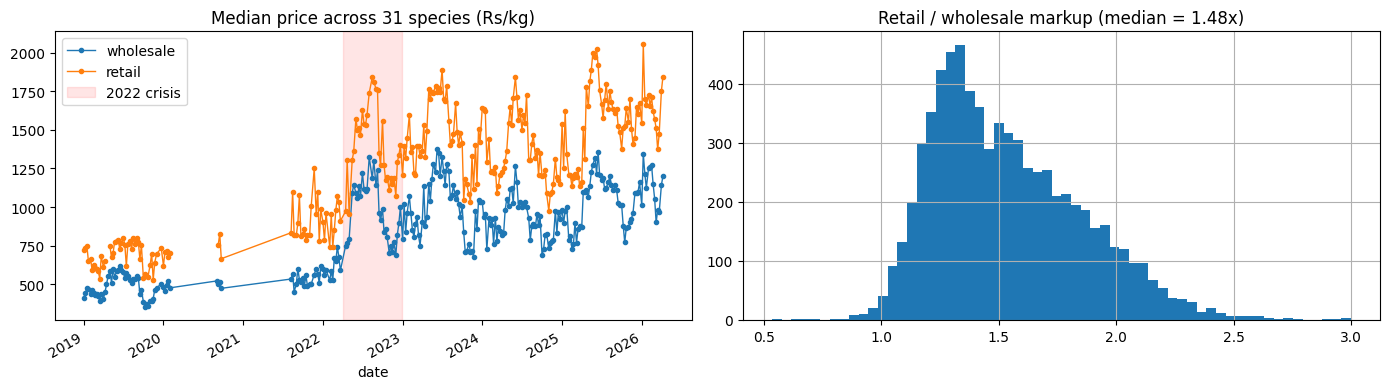

Reports per year:
date
2019    46
2020     9
2021    18
2022    43
2023    48
2024    48
2025    48
2026    14
Name: date, dtype: int64


In [28]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
med = wide.groupby("date")[["wholesale", "retail"]].median()
med.plot(ax=ax[0], marker=".", lw=1)
ax[0].set_title("Median price across 31 species (Rs/kg)")
ax[0].axvspan(pd.Timestamp("2022-04-01"), pd.Timestamp("2022-12-31"), color="red", alpha=0.1, label="2022 crisis")
ax[0].legend()

markup = (wide["retail"] / wide["wholesale"]).dropna()
markup.clip(0.5, 3).hist(bins=60, ax=ax[1])
ax[1].set_title(f"Retail / wholesale markup (median = {markup.median():.2f}x)")
plt.tight_layout(); plt.show()

print("Reports per year:")
print(wide.groupby(wide["date"].dt.year)["date"].nunique())

- Prices roughly **doubled between 2021 and 2023** (the economic crisis).
- 2020–2021 has only about 22 reports (COVID disruption), so the series has gaps.

## 5. Feature engineering
**Target:** the retail price this week.\
**Prediction:** models predict the `log(retail / wholesale)`.
I then convert back with `retail = wholesale × exp(prediction)`.\
**Reason:** tree models cannot predict values outside their training range.

| Feature | Meaning |
|---|---|
| `log_wholesale` | this week's wholesale price (log) |
| `log_wholesale_lag1` | last report's wholesale price |
| `log_wholesale_roll4` | 4-report average wholesale price |
| `wholesale_change` | % change in wholesale since last report (log difference) |
| `log_market_index` | median wholesale price of all species this week (general price level / inflation) |
| `month`, `week` | season |
| `sw_monsoon`, `ne_monsoon` | monsoon seasons that affect fishing (SW: May–Sep, NE: Dec–Feb) |
| `sp_*` | species (one-hot encoded) |

In [29]:
# [AI assisted]
def make_features(w):
    w = w.sort_values(["species", "date"]).copy()
    g = w.groupby("species")["wholesale"]
    w["wholesale_lag1"] = g.shift(1)
    w["wholesale_roll4"] = g.transform(lambda s: s.rolling(4, min_periods=1).mean())
    w["market_index"] = w.groupby("date")["wholesale"].transform("median")
    out = pd.DataFrame(index=w.index)
    out["log_wholesale"] = np.log(w["wholesale"])
    out["log_wholesale_lag1"] = np.log(w["wholesale_lag1"])
    out["log_wholesale_roll4"] = np.log(w["wholesale_roll4"])
    out["wholesale_change"] = out["log_wholesale"] - out["log_wholesale_lag1"]
    out["log_market_index"] = np.log(w["market_index"])
    out["month"] = w["date"].dt.month
    out["week"] = w["date"].dt.isocalendar().week.astype(int)
    out["sw_monsoon"] = out["month"].isin([5, 6, 7, 8, 9]).astype(int)
    out["ne_monsoon"] = out["month"].isin([12, 1, 2]).astype(int)
    sp = pd.get_dummies(w["species"], prefix="sp", dtype=float)
    sp.columns = [re.sub(r"\W+", "_", c) for c in sp.columns]
    return pd.concat([out, sp], axis=1), w


X_all, W = make_features(wide)
mask = W["wholesale"].notna() & W["retail"].notna()
X_all, W = X_all[mask], W[mask]

X_all["log_wholesale_lag1"] = X_all["log_wholesale_lag1"].fillna(X_all["log_wholesale"])
X_all["wholesale_change"] = X_all["wholesale_change"].fillna(0)

y_all = np.log(W["retail"] / W["wholesale"])
FEATURES = list(X_all.columns)
print(X_all.shape, "features:", len(FEATURES))

(7127, 40) features: 40


## 6. Train/test split (by time, not random)
- **Train:** Jan 2019 – Dec 2023
- **Test:** Jan 2024 – Apr 2026



In [30]:
# [AI-GENERATED]
order = np.argsort(W["date"].values, kind="stable")
X_all, y_all, W = X_all.iloc[order], y_all.iloc[order], W.iloc[order]

is_train = (W["date"] < "2024-01-01").values
X_tr, X_te = X_all[is_train], X_all[~is_train]
y_tr, y_te = y_all[is_train], y_all[~is_train]
W_tr, W_te = W[is_train], W[~is_train]
print(f"train {len(X_tr)} rows ({W_tr.date.min().date()} → {W_tr.date.max().date()})")
print(f"test  {len(X_te)} rows ({W_te.date.min().date()} → {W_te.date.max().date()})")

def to_price(log_markup, wholesale):
    return wholesale * np.exp(log_markup)

def scores(actual, pred):
    return dict(MAE=mean_absolute_error(actual, pred),
                RMSE=np.sqrt(mean_squared_error(actual, pred)),
                MAPE=100 * mean_absolute_percentage_error(actual, pred),
                R2=r2_score(actual, pred))

train 4139 rows (2019-01-01 → 2023-12-22)
test  2988 rows (2024-01-01 → 2026-04-08)


## 7. Models
| Family | Model |
|---|---|
| Baseline | **Species median markup** |
| Baseline | Ridge regression |
| Single tree | Decision tree |
| **Bagging** | Bagging (decision trees) |
| **Bagging** | Random forest |
| **Boosting** | AdaBoost |
| **Boosting** | Gradient boosting (GBM) |
| **Boosting** | LightGBM |
| **Boosting** | CatBoost |
| **Stacking** | Stacking (RF, Bagging, LightGBM, CatBoost, Ridge → Ridge meta-model) |
| **Hybrid** | RF + ANN (average of a random forest and a neural network) |

In [31]:
def build_models():
    return {
        "Ridge": Ridge(alpha=1.0),
        "Decision Tree": DecisionTreeRegressor(random_state=SEED),
        "Bagging (DT)": BaggingRegressor(DecisionTreeRegressor(), n_estimators=200,
                                         random_state=SEED, n_jobs=-1),
        "Random Forest": RandomForestRegressor(n_estimators=400, max_features=0.5, min_samples_leaf=2,
                                               random_state=SEED, n_jobs=-1),
        "AdaBoost": AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), n_estimators=200,
                                      learning_rate=0.05, random_state=SEED),
        "GBM": GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=3,
                                         subsample=0.8, random_state=SEED),
        "LightGBM": LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, subsample=0.8,
                                  subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),
        "CatBoost": CatBoostRegressor(iterations=800, learning_rate=0.05, depth=6,
                                      random_seed=SEED, verbose=0),
        "Stacking": StackingRegressor(
            estimators=[
                ("rf", RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=2,
                                             random_state=SEED, n_jobs=-1)),
                ("bag", BaggingRegressor(DecisionTreeRegressor(), n_estimators=100,
                                         random_state=SEED, n_jobs=-1)),
                ("lgbm", LGBMRegressor(n_estimators=600, learning_rate=0.03, subsample=0.8, subsample_freq=1,
                                       colsample_bytree=0.8, random_state=SEED, verbose=-1)),
                ("cat", CatBoostRegressor(iterations=800, learning_rate=0.05, depth=6,
                                          random_seed=SEED, verbose=0)),
                ("ridge", Ridge(alpha=1.0)),
            ],
            final_estimator=RidgeCV(alphas=[0.01, 0.1, 1, 10]),
            cv=KFold(5, shuffle=False), n_jobs=1),
        "Hybrid RF + ANN": VotingRegressor([
            ("rf", RandomForestRegressor(n_estimators=400, max_features=0.5, min_samples_leaf=2,
                                         random_state=SEED, n_jobs=-1)),
            ("ann", make_pipeline(StandardScaler(),
                                  MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=2000,
                                               early_stopping=True, random_state=SEED))),
        ]),
    }
FAMILY = {"Species median (baseline)": "Baseline", "Ridge": "Baseline", "Decision Tree": "Single tree",
          "Bagging (DT)": "Bagging", "Random Forest": "Bagging", "AdaBoost": "Boosting", "GBM": "Boosting",
          "LightGBM": "Boosting", "CatBoost": "Boosting", "Stacking": "Stacking", "Hybrid RF + ANN": "Hybrid"}

## 8. Time-series cross-validation on the training period

In [32]:
# [AI-GENERATED]
tscv = TimeSeriesSplit(n_splits=5)
cv_rows = []
for name, model in build_models().items():
    t0 = time.time(); fold_mape = []
    for tr_idx, va_idx in tscv.split(X_tr):
        model.fit(X_tr.iloc[tr_idx], y_tr.iloc[tr_idx])
        p = to_price(model.predict(X_tr.iloc[va_idx]), W_tr["wholesale"].values[va_idx])
        fold_mape.append(100 * mean_absolute_percentage_error(W_tr["retail"].values[va_idx], p))
    cv_rows.append(dict(model=name, family=FAMILY[name], cv_mape_mean=np.mean(fold_mape),
                        cv_mape_std=np.std(fold_mape), seconds=time.time() - t0))
    print(f"{name:18s} CV MAPE {np.mean(fold_mape):5.2f}% ± {np.std(fold_mape):4.2f}")
cv_df = pd.DataFrame(cv_rows)
cv_df.to_csv("results/metrics_cv.csv", index=False)

Ridge              CV MAPE 11.49% ± 2.43
Decision Tree      CV MAPE 14.90% ± 2.72
Bagging (DT)       CV MAPE 11.56% ± 2.95
Random Forest      CV MAPE 11.64% ± 2.86
AdaBoost           CV MAPE 14.24% ± 1.29
GBM                CV MAPE 11.36% ± 2.61
LightGBM           CV MAPE 11.51% ± 2.69
CatBoost           CV MAPE 11.20% ± 2.54
Stacking           CV MAPE 10.93% ± 2.34
Hybrid RF + ANN    CV MAPE 11.61% ± 3.00


## 9. Final training and testing

In [33]:
species_cols = [c for c in FEATURES if c.startswith("sp_")]
train_species = W_tr["species"].values
median_markup = pd.Series(y_tr.values).groupby(train_species).median()
global_markup = float(np.median(y_tr))
def baseline_predict(Wpart):
    return Wpart["species"].map(median_markup).fillna(global_markup).values

fitted, test_rows, train_rows = {}, [], []
preds = pd.DataFrame({"date": W_te["date"].values, "species": W_te["species"].values,
                      "wholesale": W_te["wholesale"].values, "actual": W_te["retail"].values})

p_base = to_price(baseline_predict(W_te), W_te["wholesale"].values)
preds["Species median (baseline)"] = p_base
test_rows.append(dict(model="Species median (baseline)", **scores(W_te["retail"], p_base)))
train_rows.append(dict(model="Species median (baseline)",
                       **scores(W_tr["retail"], to_price(baseline_predict(W_tr), W_tr["wholesale"].values))))

for name, model in build_models().items():
    t0 = time.time()
    model.fit(X_tr, y_tr)
    fitted[name] = model
    p_te = to_price(model.predict(X_te), W_te["wholesale"].values)
    p_tr = to_price(model.predict(X_tr), W_tr["wholesale"].values)
    preds[name] = p_te
    test_rows.append(dict(model=name, **scores(W_te["retail"], p_te), fit_seconds=time.time() - t0))
    train_rows.append(dict(model=name, **scores(W_tr["retail"], p_tr)))
    print(f"{name:18s} test MAPE {test_rows[-1]['MAPE']:5.2f}%  ({time.time()-t0:.1f}s)")

test_df = pd.DataFrame(test_rows); test_df["family"] = test_df["model"].map(FAMILY)
train_df = pd.DataFrame(train_rows)
leader = (test_df.merge(train_df[["model", "MAPE"]].rename(columns={"MAPE": "train_MAPE"}), on="model")
                 .merge(cv_df[["model", "cv_mape_mean", "cv_mape_std"]], on="model", how="left")
                 .sort_values("MAPE"))
leader.to_csv("results/metrics_test.csv", index=False)
preds.to_csv("results/predictions_test.csv", index=False)
leader[["model", "family", "MAE", "RMSE", "MAPE", "R2", "train_MAPE", "cv_mape_mean", "cv_mape_std"]].round(3)

Ridge              test MAPE  8.20%  (0.0s)
Decision Tree      test MAPE  9.46%  (0.1s)
Bagging (DT)       test MAPE  6.89%  (11.5s)
Random Forest      test MAPE  7.15%  (10.3s)
AdaBoost           test MAPE 14.45%  (3.6s)
GBM                test MAPE  7.71%  (4.3s)
LightGBM           test MAPE  6.98%  (1.5s)
CatBoost           test MAPE  7.35%  (3.2s)
Stacking           test MAPE  7.25%  (72.8s)
Hybrid RF + ANN    test MAPE  6.87%  (11.7s)


,model,family,MAE,RMSE,MAPE,R2,train_MAPE,cv_mape_mean,cv_mape_std
10,Hybrid RF + ANN,Hybrid,110.458,153.233,6.872,0.970,5.256,11.615,2.999
3,Bagging (DT),Bagging,112.306,157.252,6.894,0.968,3.052,11.559,2.951
7,LightGBM,Boosting,114.286,158.239,6.978,0.968,5.136,11.507,2.692
4,Random Forest,Bagging,118.477,167.907,7.147,0.964,4.093,11.644,2.862
9,Stacking,Stacking,120.841,168.933,7.255,0.963,7.342,10.925,2.343
8,CatBoost,Boosting,121.115,169.759,7.353,0.963,5.907,11.199,2.542
6,GBM,Boosting,129.420,180.805,7.711,0.958,7.850,11.363,2.608
1,Ridge,Baseline,142.975,204.612,8.202,0.946,9.710,11.488,2.427
2,Decision Tree,Single tree,151.725,206.367,9.465,0.945,0.000,14.904,2.725
0,Species median (baseline),Baseline,157.185,216.715,9.605,0.939,12.160,NaN,NaN


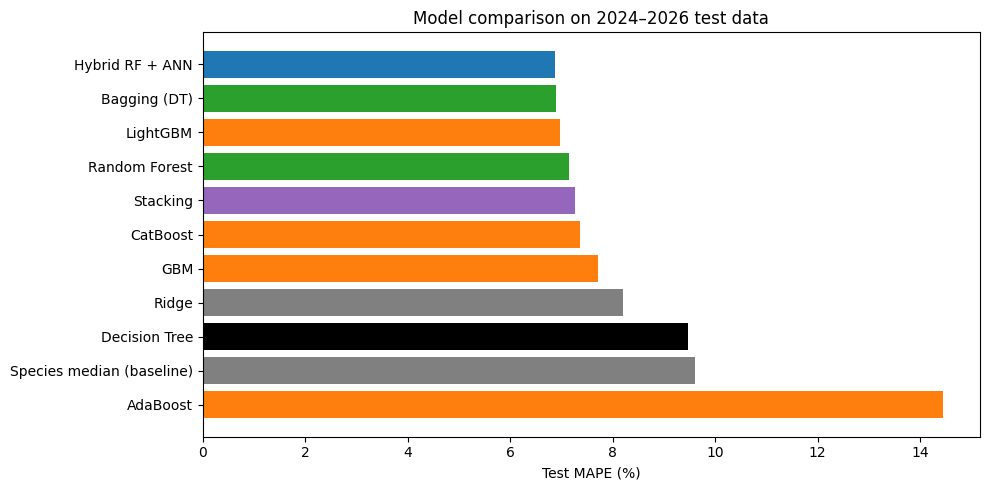

In [34]:
# [AI-GENERATED]
fig, ax = plt.subplots(figsize=(10, 5))
colors = {"Baseline": "grey", "Single tree": "black", "Bagging": "tab:green", "Boosting": "tab:orange",
          "Stacking": "tab:purple", "Hybrid": "tab:blue"}
lb = leader.sort_values("MAPE", ascending=False)
ax.barh(lb["model"], lb["MAPE"], color=lb["family"].map(colors))
ax.set_xlabel("Test MAPE (%)"); ax.set_title("Model comparison on 2024–2026 test data")
plt.tight_layout(); plt.show()

## 10. Why do the models behave this way?

### 10.1 Bias vs variance: training error vs test error

In [35]:
# [AI-GENERATED]
bv = leader[["model", "family", "train_MAPE", "MAPE"]].rename(columns={"MAPE": "test_MAPE"})
bv["gap"] = bv["test_MAPE"] - bv["train_MAPE"]
bv.to_csv("results/bias_variance.csv", index=False)
bv.round(2)

,model,family,train_MAPE,test_MAPE,gap
10,Hybrid RF + ANN,Hybrid,5.26,6.87,1.62
3,Bagging (DT),Bagging,3.05,6.89,3.84
7,LightGBM,Boosting,5.14,6.98,1.84
4,Random Forest,Bagging,4.09,7.15,3.05
9,Stacking,Stacking,7.34,7.25,-0.09
8,CatBoost,Boosting,5.91,7.35,1.45
6,GBM,Boosting,7.85,7.71,-0.14
1,Ridge,Baseline,9.71,8.20,-1.51
2,Decision Tree,Single tree,0.00,9.46,9.46
0,Species median (baseline),Baseline,12.16,9.60,-2.56


### 10.2 Effect of the number of trees: random forest (bagging) vs GBM (boosting)

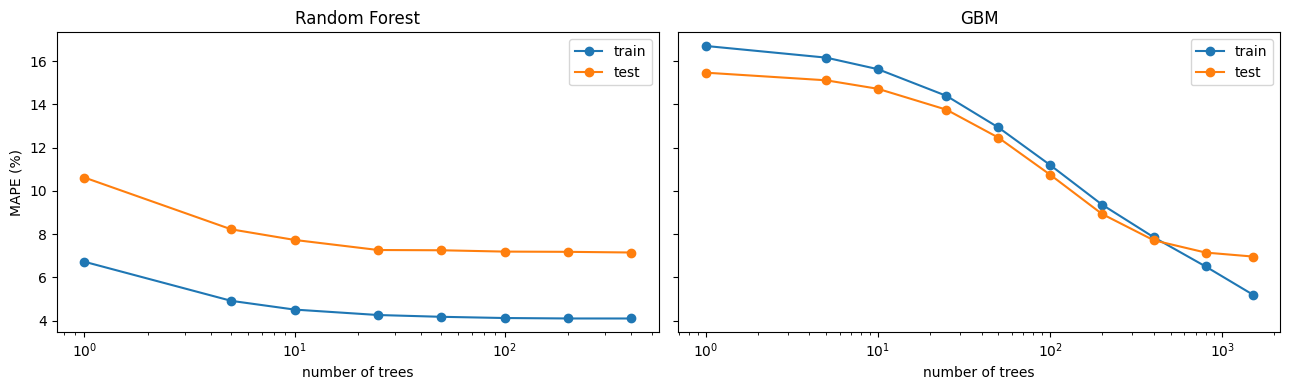

,model,n_trees,train_MAPE,test_MAPE
0,Random Forest,1,6.72,10.62
1,Random Forest,5,4.91,8.22
2,Random Forest,10,4.51,7.73
3,Random Forest,25,4.25,7.26
4,Random Forest,50,4.17,7.25
5,Random Forest,100,4.12,7.19
6,Random Forest,200,4.09,7.18
7,Random Forest,400,4.09,7.15
8,GBM,1,16.70,15.47
9,GBM,5,16.16,15.12


In [36]:
curve = []
for n in [1, 5, 10, 25, 50, 100, 200, 400]:
    rf = RandomForestRegressor(n_estimators=n, max_features=0.5, min_samples_leaf=2,
                               random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
    curve.append(dict(model="Random Forest", n_trees=n,
                      train_MAPE=100*mean_absolute_percentage_error(W_tr.retail, to_price(rf.predict(X_tr), W_tr.wholesale)),
                      test_MAPE=100*mean_absolute_percentage_error(W_te.retail, to_price(rf.predict(X_te), W_te.wholesale))))
gbm = GradientBoostingRegressor(n_estimators=1500, learning_rate=0.05, max_depth=3, subsample=0.8,
                                random_state=SEED).fit(X_tr, y_tr)
tr_stage = list(gbm.staged_predict(X_tr)); te_stage = list(gbm.staged_predict(X_te))
for n in [1, 5, 10, 25, 50, 100, 200, 400, 800, 1500]:
    curve.append(dict(model="GBM", n_trees=n,
                      train_MAPE=100*mean_absolute_percentage_error(W_tr.retail, to_price(tr_stage[n-1], W_tr.wholesale)),
                      test_MAPE=100*mean_absolute_percentage_error(W_te.retail, to_price(te_stage[n-1], W_te.wholesale))))
curve = pd.DataFrame(curve); curve.to_csv("results/ntrees_curve.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, m in zip(ax, ["Random Forest", "GBM"]):
    c = curve[curve.model == m]
    a.plot(c.n_trees, c.train_MAPE, "o-", label="train"); a.plot(c.n_trees, c.test_MAPE, "o-", label="test")
    a.set_xscale("log"); a.set_title(m); a.set_xlabel("number of trees"); a.legend()
ax[0].set_ylabel("MAPE (%)"); plt.tight_layout(); plt.show()
curve.round(2)

### 10.3 Why stacking does not improve much of the performance?

In [37]:
base_names = ["Random Forest", "Bagging (DT)", "LightGBM", "CatBoost", "Ridge", "Hybrid RF + ANN"]
resid = pd.DataFrame({m: preds[m] - preds["actual"] for m in base_names})
corr = resid.corr(); corr.to_csv("results/residual_corr.csv")
stack = fitted["Stacking"]
weights = pd.DataFrame({"base_model": ["Random Forest", "Bagging (DT)", "LightGBM", "CatBoost", "Ridge"],
                        "meta_weight": stack.final_estimator_.coef_})
weights.to_csv("results/stack_weights.csv", index=False)
print(corr.round(2)); print(); print(weights.round(3))

                 Random Forest  Bagging (DT)  LightGBM  CatBoost  Ridge  \
Random Forest             1.00          0.97      0.91      0.91   0.55   
Bagging (DT)              0.97          1.00      0.89      0.87   0.53   
LightGBM                  0.91          0.89      1.00      0.94   0.58   
CatBoost                  0.91          0.87      0.94      1.00   0.61   
Ridge                     0.55          0.53      0.58      0.61   1.00   
Hybrid RF + ANN           0.89          0.90      0.88      0.88   0.58   

                 Hybrid RF + ANN  
Random Forest               0.89  
Bagging (DT)                0.90  
LightGBM                    0.88  
CatBoost                    0.88  
Ridge                       0.58  
Hybrid RF + ANN             1.00  

      base_model  meta_weight
0  Random Forest       -0.607
1   Bagging (DT)        0.346
2       LightGBM        0.311
3       CatBoost        0.439
4          Ridge        0.470


### 10.4 Which features matter?

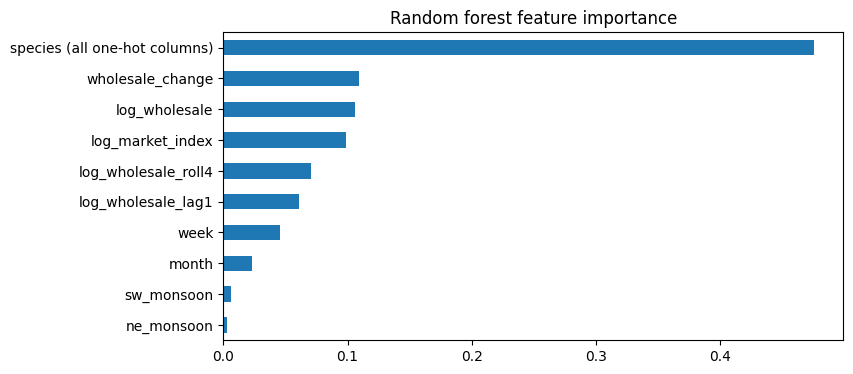

In [38]:
imp = pd.Series(fitted["Random Forest"].feature_importances_, index=FEATURES)
grouped = imp[[c for c in FEATURES if not c.startswith("sp_")]].copy()
grouped["species (all one-hot columns)"] = imp[[c for c in FEATURES if c.startswith("sp_")]].sum()
grouped = grouped.sort_values(ascending=False)
grouped.rename("importance").to_frame().to_csv("results/importance.csv")
grouped.plot.barh(figsize=(8, 4), title="Random forest feature importance"); plt.gca().invert_yaxis(); plt.show()

### 10.5 Raw price target vs markup target

In [39]:
lvl_rows = []
y_tr_level, y_te_level = np.log(W_tr["retail"]), np.log(W_te["retail"])
for name in ["Ridge", "Random Forest", "LightGBM"]:
    m = build_models()[name].fit(X_tr, y_tr_level)
    p = np.exp(m.predict(X_te))
    lvl_rows.append(dict(model=name, target="raw log price", MAPE=100*mean_absolute_percentage_error(W_te.retail, p)))
    lvl_rows.append(dict(model=name, target="log markup", MAPE=float(leader.set_index("model").loc[name, "MAPE"])))
    if name == "Random Forest": preds["Random Forest (raw-price target)"] = p
lvl = pd.DataFrame(lvl_rows); lvl.to_csv("results/level_vs_markup.csv", index=False)
print(lvl.pivot(index="model", columns="target", values="MAPE").round(2))
print("Highest retail price in training:", W_tr.retail.max(), "| in test:", W_te.retail.max())
preds.to_csv("results/predictions_test.csv", index=False)

target         log markup  raw log price
model                                   
LightGBM             6.98           7.32
Random Forest        7.15           8.38
Ridge                8.20           8.20
Highest retail price in training: 4390.0 | in test: 4870.0


### 10.6 Where does the best model make mistakes?

In [40]:
best = leader.iloc[0]["model"]; print("Best model on test:", best)
sp_err = (preds.assign(err_best=lambda d: (d[best] - d.actual).abs() / d.actual * 100,
                       err_base=lambda d: (d["Species median (baseline)"] - d.actual).abs() / d.actual * 100)
               .groupby("species")[["err_best", "err_base"]].mean().sort_values("err_best"))
sp_err.columns = [f"{best} MAPE %", "Baseline MAPE %"]
sp_err.to_csv("results/species_error.csv")
sp_err.round(1)

Best model on test: Hybrid RF + ANN


,Hybrid RF + ANN MAPE %,Baseline MAPE %
species,,
Prawns (M),3.6,5.3
Sail fish,3.8,5.1
Rock fish (L),4.2,7.4
Marlins,4.5,9.9
Trevally (L),4.8,7.1
Sea Crabs (L),5.2,7.6
Indian Scade,5.6,7.7
Sharks,5.8,11.4
Kawakawa,5.9,8.7


## 11. Save models for the dashboard


In [ ]:

def light_models():
    rf100 = lambda: RandomForestRegressor(n_estimators=100, max_features=0.5, min_samples_leaf=3,
                                          random_state=SEED, n_jobs=-1)
    bag50 = lambda: BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=2), n_estimators=50,
                                     random_state=SEED, n_jobs=-1)
    full = build_models()
    return {
        "Random Forest": rf100(), "Bagging (DT)": bag50(),
        "LightGBM": full["LightGBM"], "CatBoost": full["CatBoost"], "Ridge": full["Ridge"],
        "Stacking": StackingRegressor(
            estimators=[("rf", rf100()), ("bag", bag50()),
                        ("lgbm", full["LightGBM"]), ("cat", full["CatBoost"]), ("ridge", Ridge(alpha=1.0))],
            final_estimator=RidgeCV(alphas=[0.01, 0.1, 1, 10]), cv=KFold(5, shuffle=False)),
        "Hybrid RF + ANN": VotingRegressor([("rf", rf100()), ("ann", make_pipeline(StandardScaler(),
                              MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=2000,
                                           early_stopping=True, random_state=SEED)))]),
    }
app_models, app_rows = {}, []
for name, m in light_models().items():
    m.fit(X_tr, y_tr); app_models[name] = m
    p = to_price(m.predict(X_te), W_te["wholesale"].values)
    app_rows.append(dict(model=name, **scores(W_te["retail"], p)))
pd.DataFrame(app_rows).to_csv("results/app_models_test.csv", index=False)
print(pd.DataFrame(app_rows).round(2))

             model     MAE    RMSE  MAPE    R2
0    Random Forest  119.93  170.23  7.23  0.96
1     Bagging (DT)  112.67  158.15  6.92  0.97
2         LightGBM  114.29  158.24  6.98  0.97
3         CatBoost  121.11  169.76  7.35  0.96
4            Ridge  142.98  204.61  8.20  0.95
5         Stacking  121.07  169.36  7.25  0.96
6  Hybrid RF + ANN  110.81  153.45  6.89  0.97


In [42]:
# [AI-GENERATED]
latest = W.sort_values("date").groupby("species").tail(1).set_index("species")
bundle = dict(
    models=app_models,
    features=FEATURES, median_markup=median_markup.to_dict(), global_markup=global_markup,
    species=sorted(W["species"].unique()),
    latest_wholesale=latest["wholesale"].to_dict(),
    latest_market_index=float(np.exp(X_all["log_market_index"].iloc[-1])),
    best_model=best, train_end="2023-12-31", test_start="2024-01-01",
)
joblib.dump(bundle, "models/model_bundle.joblib", compress=3)
wide.to_csv("results/wide_prices.csv", index=False)
print("Saved:", os.path.getsize("models/model_bundle.joblib") / 1e6, "MB")

Saved: 18.404829 MB


## 12. References
- Data: Ministry of Fisheries weekly fish price reports, via `github.com/nuuuwan/lk_datasets` (dataset 024).
- scikit-learn, LightGBM and CatBoost documentation.


In [43]:
!zip -r outputs.zip models results
from google.colab import files; files.download("outputs.zip")
import sklearn, lightgbm, catboost
print("scikit-learn", sklearn.__version__, "| lightgbm", lightgbm.__version__, "| catboost", catboost.__version__)

updating: models/ (stored 0%)
updating: models/model_bundle.joblib (deflated 1%)
updating: results/ (stored 0%)
updating: results/ntrees_curve.csv (deflated 49%)
updating: results/fish_prices_long.csv (deflated 86%)
updating: results/predictions_test.csv (deflated 54%)
updating: results/residual_corr.csv (deflated 59%)
updating: results/species_error.csv (deflated 39%)
updating: results/bias_variance.csv (deflated 40%)
updating: results/wide_prices.csv (deflated 80%)
updating: results/importance.csv (deflated 38%)
updating: results/stack_weights.csv (deflated 17%)
updating: results/metrics_cv.csv (deflated 39%)
updating: results/metrics_test.csv (deflated 43%)
updating: results/level_vs_markup.csv (deflated 38%)
updating: results/app_models_test.csv (deflated 37%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

scikit-learn 1.6.1 | lightgbm 4.6.0 | catboost 1.2.10
